In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, spearmanr
import python_anesthesia_simulator as pas

In [ ]:
# Load data
data = pd.read_csv('data/database.csv')
data = data.drop(columns=['BIS_sim'])
bis = []
for caseid, data_case in data.groupby('caseid'):
    bis_model = pas.BIS_model(hill_model='Fuentes', age=data_case['age'].iloc[0])
    # e0_init = bis_model.E0
    # bis_model.E0 = data_case['BIS'].iloc[0]
    # bis_model.Emax *= bis_model.E0 / e0_init
    bis_case = bis_model.compute_bis(data_case['Ce_prop'].values, data_case['Ce_remi'].values)
    bis+=list(bis_case)
data.insert(0, "BIS_sim", bis)

data['TPR'] = (data['MAP'] / (data['HR'] * data['SV'])).clip(0, 0.04)
data['TPR_sim'] = (data['MAP_sim'] / (data['HR_sim'] * data['SV_sim'])).clip(0, 0.04)

# Compare before and after start of operation

To account for variability in opstart definition, we are comparing the mean value during 10 minute before start of operation to the start and mean value during the 10 minute after start of operation.

In [ ]:
signal_list = ['BIS', 'MAP', 'HR', 'SV']
list_of_df = []
max_period = 10 # include max_period minute before and after
min_period = 5 # exclude min_period minute before and after
for caseid, data_case in data.groupby('caseid'):
    data_case.reset_index(inplace=True)

    # opstart values
    opstart = int(data_case['opstart'].iloc[0])
    # if opstart>60*60:
    #     print(f"case {caseid} opstart too long")
    #     continue
    data_before = data_case.iloc[opstart - max_period*60: opstart-min_period*60]
    data_after = data_case.iloc[opstart+min_period*60: opstart + max_period*60]
    data_during = data_case.iloc[opstart-min_period*60: opstart + min_period*60]
    line = data_case.loc[0,['caseid', 'age', 'weight', 'height', 'bmi', 'sex', 'approach']]
    line = pd.DataFrame(line).transpose()
    for signal in signal_list:
        line.insert(0, f"{signal}_diff_before", data_before[signal].median() - data_before[f"{signal}_sim"].median())
        line.insert(0, f"{signal}_diff_after", data_after[signal].median() - data_after[f"{signal}_sim"].median())
        line.insert(0, f"{signal}_diff_max_before", data_before[signal].max() - data_before[f"{signal}_sim"].max())
        line.insert(0, f"{signal}_diff_max_after", data_after[signal].max() - data_after[f"{signal}_sim"].max())
        line.insert(0, f"{signal}_diff_max_during", data_during[signal].max() - data_during[f"{signal}_sim"].max())
    line.insert(0, 'remi_ce_opstart', data_case['Ce_remi'].iloc[opstart])
    line.insert(0, 'propo_ce_opstart', data_case['Ce_prop'].iloc[opstart])

    # intubation values
    intubation_time = opstart = int(data_case['intubation_time'].iloc[0])
    data_during = data_case.iloc[intubation_time-min_period*60: intubation_time + min_period*60]
    for signal in signal_list:
        line.insert(0, f"{signal}_diff_max_during_intub", data_during[signal].max() - data_during[f"{signal}_sim"].max())
    line.insert(0, 'remi_ce_intub', data_case['Ce_remi'].iloc[intubation_time])
    line.insert(0, 'propo_ce_intub', data_case['Ce_prop'].iloc[intubation_time])
    line.insert(0, 'tol_intub', data_case['TOL_sim'].iloc[intubation_time])

    list_of_df.append(line)

result_df =  pd.concat(
    list_of_df,
    axis=0,
    ignore_index=True
)

result_df_intub = result_df.copy()
# result_df = result_df.query('approach=="Open"')

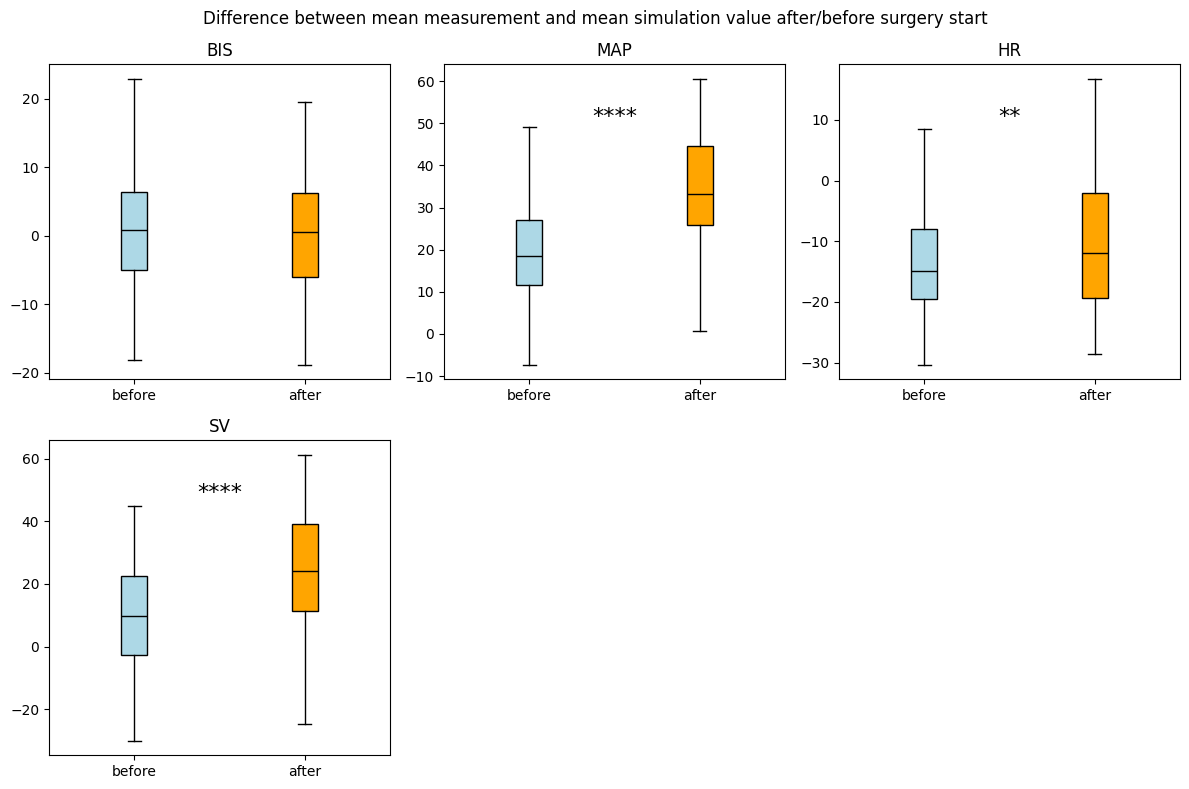

In [ ]:
plt.figure(figsize=(12, 8))

for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)

    before = result_df[f'{signal}_diff_before']
    after = result_df[f'{signal}_diff_after']

    bplot = plt.boxplot([before, after], patch_artist=True, showfliers=False)
    for patch, color in zip(bplot['boxes'], ['lightblue', 'orange']):
        patch.set_facecolor(color)
    for median in bplot['medians']:
        median.set_color('black')

    plt.xticks([1, 2], labels=['before', 'after'])
    plt.title(signal)
    stat, p_two_tailed = ttest_rel(after, before, nan_policy='omit')  # note: after - before

    # One-tailed p-value: test if after > before
    if stat > 0:
        p_one_tailed = p_two_tailed / 2
    else:
        p_one_tailed = 1 - p_two_tailed / 2

    # Significance stars
    if p_one_tailed <= 0.0001:
        stars = '****'
    elif p_one_tailed <= 0.001:
        stars = '***'
    elif p_one_tailed <= 0.01:
        stars = '**'
    elif p_one_tailed <= 0.05:
        stars = '*'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.8 * (y_lim[1]-y_lim[0])
        plt.text(1.5, y_text, stars, ha='center', va='bottom', fontsize=16, color='black')
result_df
plt.suptitle("Difference between mean measurement and mean simulation value after/before surgery start")
plt.tight_layout()
plt.show()

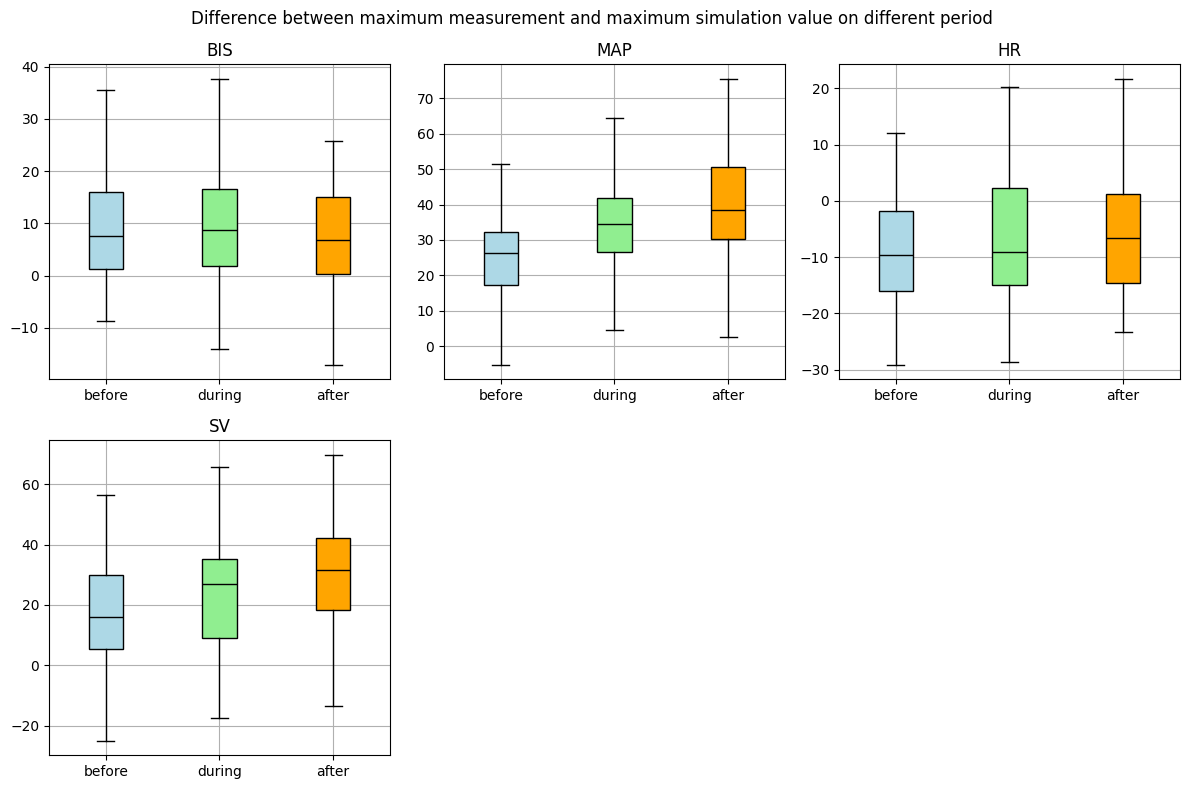

In [ ]:
plt.figure(figsize=(12, 8))
result_df
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)

    before = result_df[f'{signal}_diff_max_before']
    during = result_df[f'{signal}_diff_max_during']
    after = result_df[f'{signal}_diff_max_after']

    bplot = plt.boxplot([before, during, after], patch_artist=True, showfliers=False)
    for patch, color in zip(bplot['boxes'], ['lightblue', 'lightgreen', 'orange']):
        patch.set_facecolor(color)
    for median in bplot['medians']:
        median.set_color('black')

    plt.xticks([1, 2, 3], labels=['before', 'during', 'after'])
    plt.title(signal)
    plt.grid()

plt.suptitle("Difference between maximum measurement and maximum simulation value on different period ")
plt.tight_layout()
plt.show()

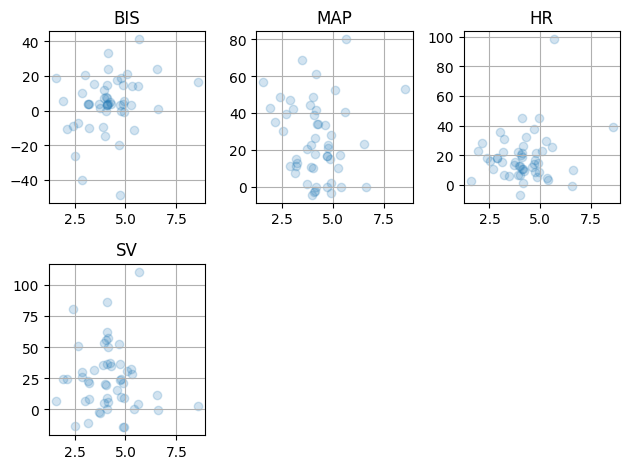

In [ ]:
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)
    x = 'remi_ce' #remi_ce, propo_ce, tol
    plt.scatter(result_df_intub[f'{x}_intub'], result_df_intub[f"{signal}_diff_max_during_intub"], alpha = 0.2)
    before_test = result_df_intub[[f'{x}_intub', f"{signal}_diff_max_during_intub"]].dropna()

    rho, p = spearmanr(before_test[f'{x}_intub'], before_test[f"{signal}_diff_max_during_intub"])
    # Significance stars
    if p <= 0.0001:
        stars = f'rho = {rho:.2E} ****'
    elif p <= 0.001:
        stars = f'rho = {rho:.2E} ***'
    elif p <= 0.01:
        stars = f'rho = {rho:.2E} **'
    elif p <= 0.05:
        stars = f'rho = {rho:.2E} *'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.9 * (y_lim[1]-y_lim[0])
        x_lim = plt.gca().get_xlim()
        x_text = x_lim[0] + 0.1 * (x_lim[1]-x_lim[0])
        plt.text(x_text, y_text, stars, ha='left', va='bottom', fontsiresult_dfze=10, color='black')

    plt.grid()
    plt.title(signal)

plt.tight_layout()
plt.show()

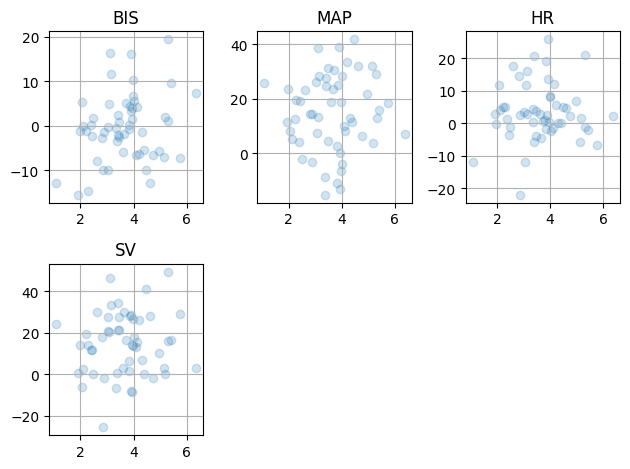

In [ ]:
for i, signal in enumerate(signal_list):
    plt.subplot(2, 3, i + 1)
    before = result_df[f'{signal}_diff_before']
    after = result_df[f'{signal}_diff_after']
    diff = after - before
    plt.scatter(result_df['remi_ce_opstart'], diff, alpha = 0.2)

    rho, p = spearmanr(result_df['remi_ce_opstart'], diff)
    # Significance stars
    if p <= 0.0001:
        stars = f'rho = {rho:.2E} ****'
    elif p <= 0.001:
        stars = f'rho = {rho:.2E} ***'
    elif p <= 0.01:
        stars = f'rho = {rho:.2E} **'
    elif p <= 0.05:
        stars = f'rho = {rho:.2E} *'
    else:
        stars = ''

    # Annotate if significant
    if stars:
        y_lim = plt.gca().get_ylim()
        y_text = y_lim[0] + 0.9 * (y_lim[1]-y_lim[0])
        plt.text(1.5, y_text, stars, ha='left', va='bottom', fontsize=10, color='black')

    plt.grid()
    plt.title(signal)

plt.tight_layout()
plt.show()

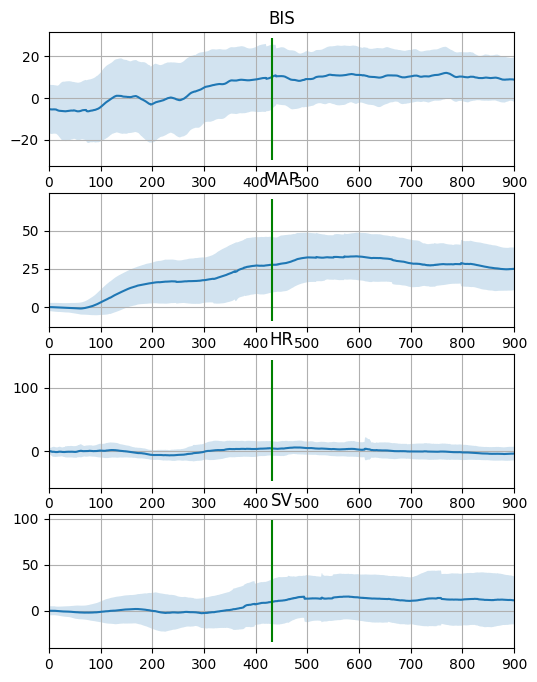

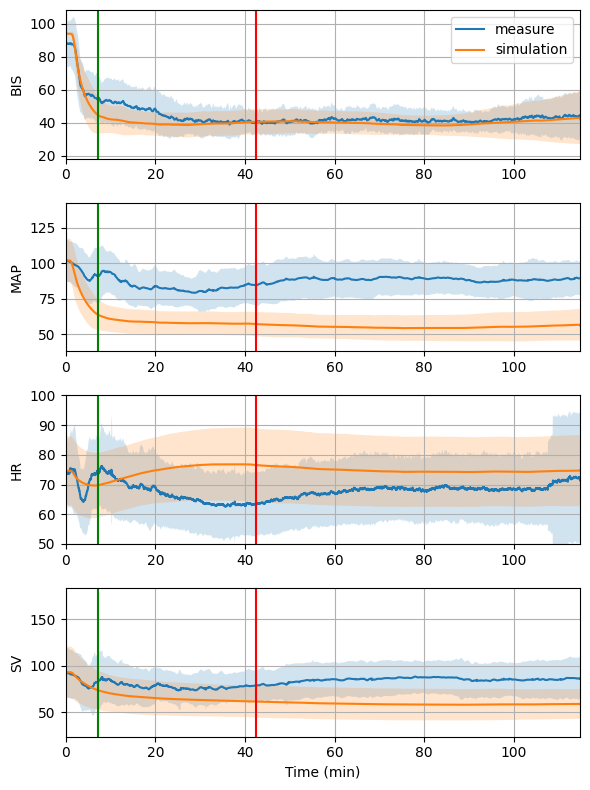

In [ ]:
min_case_duration = data.groupby('caseid')['Time'].max().min()

data['Time'] = data.groupby('caseid')['Time'].transform(lambda x: x - x.min())
intub_median = np.median(data['intubation_time'].unique())
opstart_median = np.median(data['opstart'].unique())
plt.figure(figsize=(6,8))
for i, signal in enumerate(signal_list):
    plt.subplot(4,1,i+1)
    data[f"{signal}_diff"] = data[signal] - data[f"{signal}_sim"]
    y_diff_mean = data.groupby("Time")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data.groupby("Time")[f"{signal}_diff"].std().reset_index()
    y_measure = data.groupby("Time")[signal].mean().reset_index()
    y_sim = data.groupby("Time")[f"{signal}_sim"].mean().reset_index()
    x = y_diff_mean['Time'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    plt.grid()
    ylim = plt.gca().get_ylim()
    plt.vlines(intub_median, ylim[0], ylim[1], 'g')
    plt.vlines(opstart_median, ylim[0], ylim[1], 'r')
    plt.title(signal)
    plt.xlim(0, 15*60)
plt.show()



plt.figure(figsize=(6,8))
for i, signal in enumerate(signal_list):
    plt.subplot(4,1,i+1)
    y_measure = data.groupby("Time")[signal].mean().reset_index()
    y_measure_std = data.groupby("Time")[signal].std().reset_index()
    y_sim = data.groupby("Time")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data.groupby("Time")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label= 'measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label= 'simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    x = y_diff_mean['Time'].values/60
    plt.axvline(x=intub_median/60, color='g')
    plt.axvline(x=opstart_median/60, color='r')
    plt.grid()
    plt.ylabel(signal)
    plt.xlim(0, min_case_duration/60)
    if signal=='HR':
        plt.ylim(50,100)
    
    if i==0:
        plt.legend()
plt.xlabel('Time (min)')
plt.tight_layout()
plt.savefig('output/all_signal_comparison.pdf', dpi=300)   
plt.show()

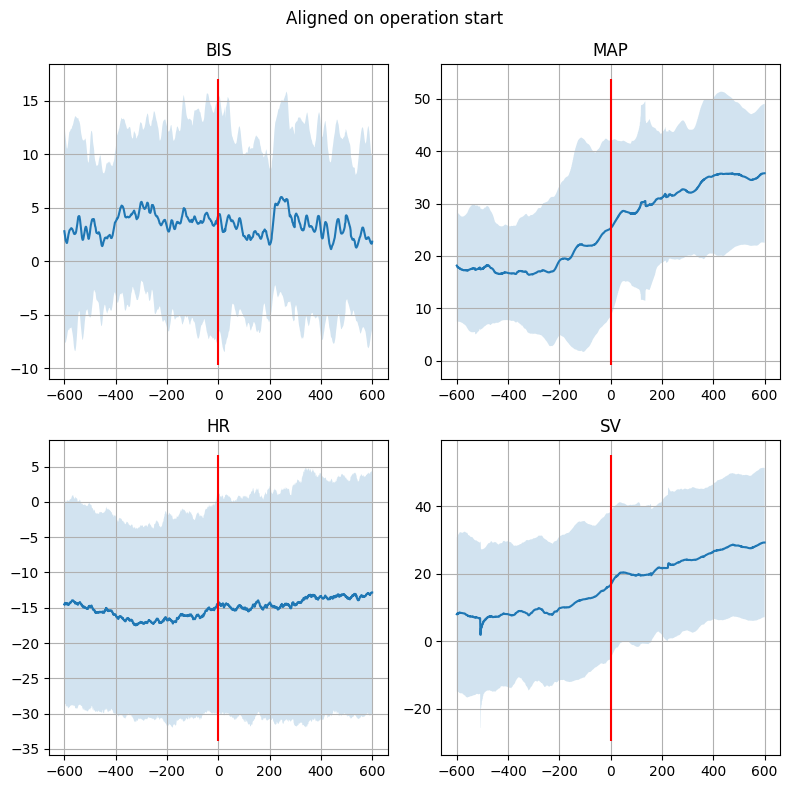

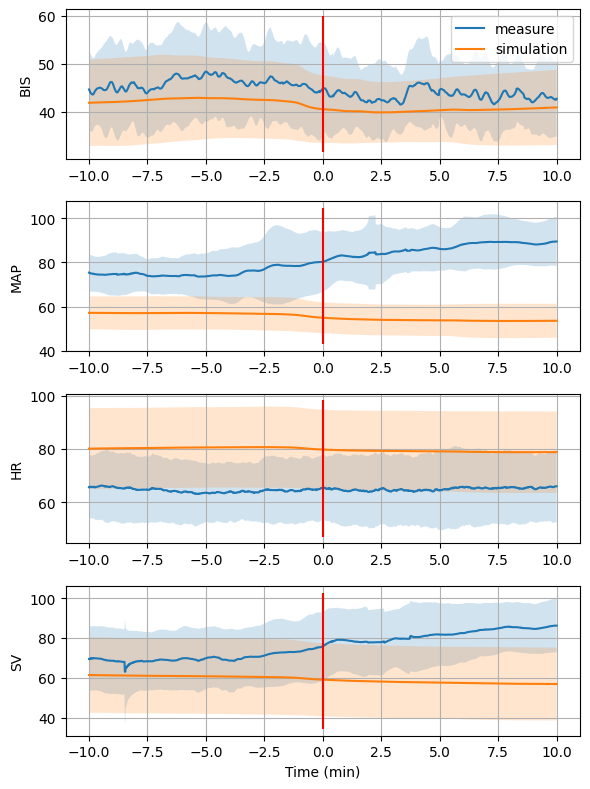

In [ ]:
data['Time_aligned'] = data['Time'] - data['opstart']
data_opstart = data.query("(Time_aligned>= -10*60) & (Time_aligned <=10*60) & (approach=='Open')").copy()
plt.figure(figsize=(8,8))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    data_opstart[f"{signal}_diff"] = data_opstart[signal] - data_opstart[f"{signal}_sim"]
    y_diff_mean = data_opstart.groupby("Time_aligned")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data_opstart.groupby("Time_aligned")[f"{signal}_diff"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.title(signal)

plt.suptitle("Aligned on operation start")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,8))
for i, signal in enumerate(signal_list):
    plt.subplot(4,1,i+1)
    y_measure = data_opstart.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_opstart.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_opstart.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_opstart.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.ylabel(signal)
    if i==0:
        plt.legend()
plt.xlabel('Time (min)')
# plt.suptitle("Aligned on operation start")IEEE system journal
plt.tight_layout()
plt.savefig('output/all_signal_opstart.pdf', dpi=300)   
plt.show()

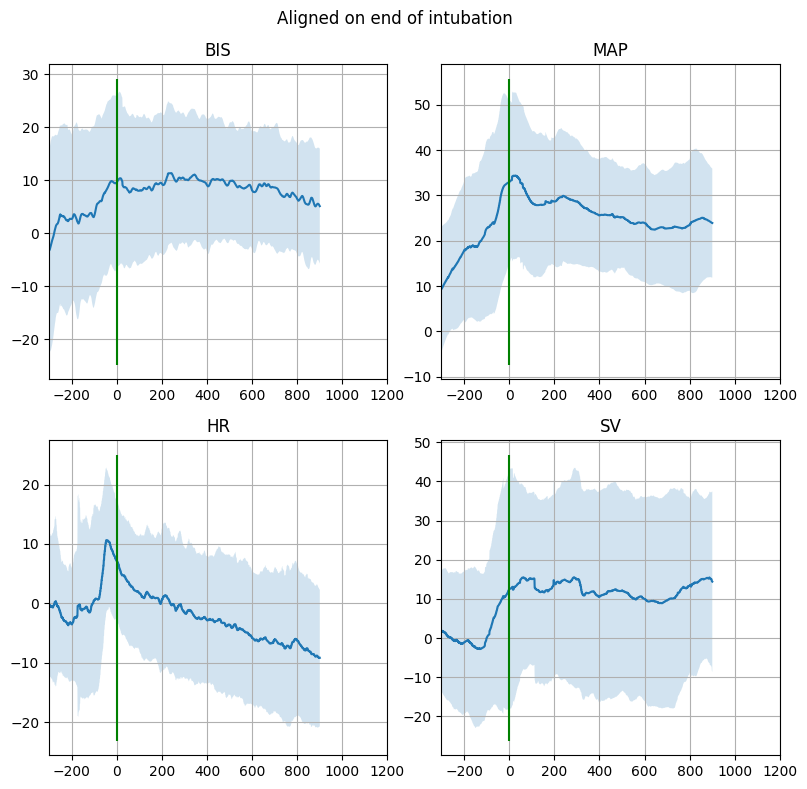

AttributeError: Line2D.set() got an unexpected keyword argument 'abel'

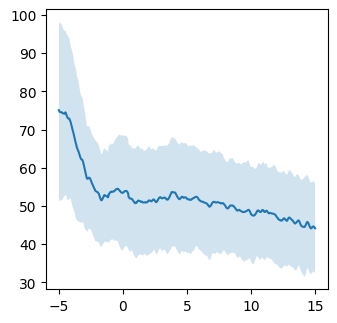

In [ ]:
data['Time_aligned'] = data['Time'] - data['intubation_time']
data_intub = data.query("(Time_aligned>= -5*60) & (Time_aligned <=15*60)").copy()
plt.figure(figsize=(8,8))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    data_intub[f"{signal}_diff"] = data_intub[signal] - data_intub[f"{signal}_sim"]
    y_diff_mean = data_intub.groupby("Time_aligned")[f"{signal}_diff"].mean().reset_index()
    y_diff_std = data_intub.groupby("Time_aligned")[f"{signal}_diff"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values
    plt.plot(x, y_diff_mean[f"{signal}_diff"].values)
    plt.fill_between(x, y_diff_mean[f"{signal}_diff"].values-y_diff_std[f"{signal}_diff"].values, y_diff_mean[f"{signal}_diff"].values+y_diff_std[f"{signal}_diff"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.title(signal)
    plt.xlim(-5*60,20*60)
plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,8))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    x = y_diff_mean['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='measure')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, abel = 'simulation')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    if i==0:
        plt.legend()
    plt.ylabel(signal)
plt.xlabel('Time (min)')
# plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.savefig('output/all_signal_intub.pdf', dpi=300)   
plt.show()

In [ ]:
perso_data = pd.read_csv("https://api.vitaldb.net/cases", decimal='.')  # personal data
caseid_list = data.caseid.unique()

perso_data = perso_data.query('caseid in @caseid_list')
perso_data['approach'].value_counts()

approach
Videoscopic    33
Open           18
Robotic         3
Name: count, dtype: int64

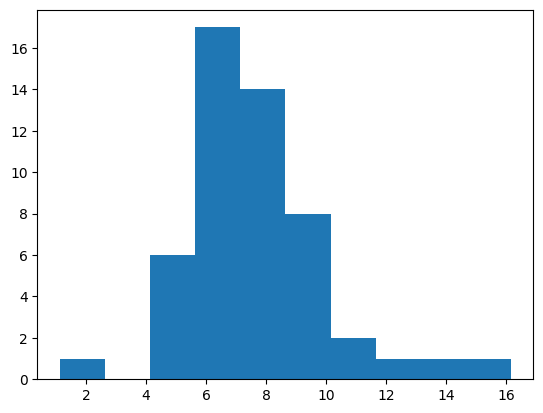

In [ ]:
plt.hist(data['intubation_time'].unique()/60)
plt.show()